In [ ]:
import numpy as np


**Pregunta 1**

In [ ]:

def gauss_seidel(A, b, x0, tol):
    x = x0.copy()
    k = 0
    normas = []
    
    while np.linalg.norm(x0 - np.linalg.inv(A) @ b) > tol and k <= 500:  # para incluir que el metodo pare en k=500
        x_ant = x.copy()
        for i in range(len(A)):
            suma1 = 0
            suma2 = 0
            for j in range(0, i):
                suma1 += A[i, j] * x[j]
            for j in range(i, len(A)-1):
                suma2 += A[i, j] * x_ant[j]
            x[i] = (b[i] - suma1 - suma2) / A[i, i]
        norma = np.linalg.norm(x - x_ant)
        normas.append(norma)
        k += 1

    return x, k, normas

In [16]:
#Función para matrices de Hilbert
def matriz_hilbert(n):
    H = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            H[i, j] = 1 / (i + j + 1)
    return H


In [23]:
n = 100
H = matriz_hilbert(n)
b = np.ones(n)
x0 = np.zeros(n)
tol = 1e-8

sol,iteraciones,normas=gauss_seidel(H,b,x0,tol)
print(normas)


[np.float64(14.397769631957969), np.float64(14.079926005712798), np.float64(17.61870167012913), np.float64(28.419411616629013), np.float64(37.09615557119684), np.float64(44.10358384424109), np.float64(50.149145036326935), np.float64(55.542937729358236), np.float64(60.457981086260986), np.float64(65.00239139497091), np.float64(69.2489780566485), np.float64(73.24950531845357), np.float64(77.04231538777049), np.float64(80.65673730939484), np.float64(84.11579531459367), np.float64(87.43795452338865), np.float64(90.63829127686783), np.float64(93.72930388886363), np.float64(96.72149012224294), np.float64(99.6237684421328), np.float64(102.4437917417915), np.float64(105.18818527027182), np.float64(107.86272999503002), np.float64(110.47250594698892), np.float64(113.02200572559273), np.float64(115.51522541857024), np.float64(117.95573819549922), np.float64(120.34675444612502), np.float64(122.69117135240027), np.float64(124.99161407779236), np.float64(127.25047024349284), np.float64(129.469918981

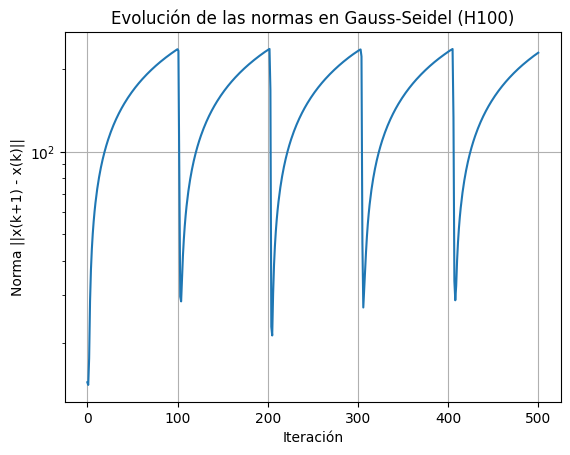

Total de iteraciones realizadas: 501
No se alcanzó la convergencia en 500 iteraciones.


In [ ]:
import matplotlib.pyplot as plt
plt.plot(normas)
plt.yscale('log')
plt.xlabel('Iteración')
plt.ylabel('Norma ||x(k+1) - x(k)||')
plt.title('Evolución de las normas en Gauss-Seidel (H100)')
plt.grid(True)
plt.show()
print(f"Total de iteraciones realizadas: {iteraciones}")
if iteraciones >= 500:
    print("No se alcanzó la convergencia en 500 iteraciones.")
else:
    print("El método Gauss-Seidel convergió exitosamente.")
    






In [ ]:
print(f'El número de condición de la matriz de Hilbert con n=100 es ' {np.})

**Conclusiones**
-La matriz de Hilbert es simétrica definida positiva, lo cual garantiza convergencia teórica del método de Gauss-Seidel.

-Sin embargo, es extremadamente mal condicionada, pues el número de condicionamiento de la matriz es : para un n=100

-Esto provoca que los errores de redondeo y las operaciones numéricas acumulen inestabilidad, dificultando la convergencia.

**Pregunta 2**

In [ ]:
#METÓDO DE LA POTENCIA INVERSA
#con err como error por iteración y niter el número por iteraciones
#mu el desplazamiento
#Reemplazaos la resolucion LU resolviendo directamente con np.linalgsolve
def potencia_inversa(A, z0, mu, tol, nmax):


    n = A.shape[0]
    M = A - mu * np.eye(n)
    q = 0 / np.linalg.norm(x0)
    res = tol + 1
    niter = 0 

    while res > tol and niter < nmax:
        niter += 1
        z = np.linalg.solve(M, q)  
        q2 = z / np.linalg.norm(z)
        lam = np.dot(q2.T, A @ q2)  
        res = np.linalg.norm(A @ q2 - lam * q2)
        costheta = abs(np.dot(q2.T, q))

        if costheta < 5e-2:
            print("Valor propio múltiple detectado (ángulo entre vectores casi ortogonal)")
            break

        q = q2

    sigma = lam
    err = res
    x = q2
    return sigma, x, niter, err  

In [25]:
#METÓDO DE LA POTENCIA 
def método_potencia (A,q,iter):
    for k in range(iter):
        z = A@ q
        q = z/np.linalg.norm(z)
        nu= q.T @ A @ q
    return nu,q

In [34]:

n = [10, 30, 50, 70]
iter = 500
mu =  1e-2  # desplazamiento 

for i in n:
    A = matriz_hilbert(i)
    z0 = np.random.rand(i)

    lambda_max, n1 = método_potencia(A, z0.copy(), iter)
    lambda_min, n2, n3, n4 = potencia_inversa(A, z0.copy(), mu, tol=1e-8, nmax=iter)

    # Por definición: número de condición espectral = |lambda_max| / |lambda_min|
    cond = abs(lambda_max) / abs(lambda_min)

    print(f"n = {i}")
    print(f"  lambda_max ≈ {lambda_max:.4e}")
    print(f"  lambda_min ≈ {lambda_min:.4e}")
    print(f"  cond. espectral ≈ {cond:.4e}")
    print("-" * 40)




    
    

    


C:\Users\lesly\AppData\Local\Temp\ipykernel_26304\3476039468.py:9: RuntimeWarning: invalid value encountered in scalar divide
  q = 0 / np.linalg.norm(x0)


ValueError: solve: Input operand 1 does not have enough dimensions (has 0, gufunc core with signature (m,m),(m,n)->(m,n) requires 2)